# 08 — Multivariate Regression Models

## Purpose

In the earlier notebooks we looked at each predictor on its own, or with one moderator at a time. In this notebook we build **multivariate OLS regression models step by step**, as in Week 5, to see which variables still matter once the others are taken into account:

| Model | Adds | Question it answers |
|---|---|---|
| **Model 1** | Mother's education (Q277R) + father's education (Q278R) | Do both parents' education levels matter when they are considered together? |
| **Model 2** | + `mother_more_educated` | Does the mother being more educated than the father matter beyond each parent's own level? |
| **Model 3** | + the moderators as predictors: religiosity, science optimism, science & faith/morality, authoritarian notions, liberal notions, regime evaluation, left–right | Does parental education still matter once respondents' religious, science and political views are included? |
| **Model 4** | + controls: female (Q260), age (Q262), own education (Q275R) | Does parental education still matter once we account for who the respondent is? |

We then:

- compare the models (R², adjusted R², change in R², AIC and F-tests);
- check for **multicollinearity** with variance inflation factors (VIFs);
- compare the sizes of the **standardised coefficients** in the final model;
- check whether the key interactions from `07_moderation.ipynb` survive the controls;
- run sensitivity checks with **HC3 robust standard errors**, with **parental education entered as categories**, and with the **authoritarian index without Q247**.

The outcome is `traditional_gender_attitudes` (1–4, **higher = more traditional**). Parental and own education are entered as numeric scores (1 = Lower, 2 = Middle, 3 = Higher), as in `07_moderation.ipynb`. This assumes that each step up in education (Lower → Middle and Middle → Higher) has the same association with attitudes. Section 8.4 checks whether this assumption matters.

## 1. Setup and Data Loading

We use the same tools as in Week 5: `smf.ols`, `anova_lm` for F-tests and `Stargazer` for the regression table. To check multicollinearity we use `variance_inflation_factor` from `statsmodels`. This was not covered in class, but it comes from a library we already use, and it is the standard way of calculating VIFs.

In [1]:
from pathlib import Path  # used to build file paths that work on any computer

import pandas as pd  # data management (DataFrames)
import numpy as np  # numerical tools
from plotnine import *  # ggplot-style figures, as used in class
import warnings  # lets us silence routine warnings
warnings.filterwarnings('ignore')  # hide warnings so the output is easier to read
import statsmodels.formula.api as smf  # OLS regression with formulas (Week 5)
import statsmodels.api as sm  # used to add the constant for the VIF calculation
from statsmodels.stats.anova import anova_lm  # F-tests for nested models (Week 5)
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIFs for multicollinearity
from stargazer.stargazer import Stargazer  # regression tables (Weeks 5 and 6)

In [2]:
# Identify the root folder of the GitHub repository.
PROJECT_ROOT = Path.cwd()  # start from the folder the notebook is running in
if PROJECT_ROOT.name == "code":  # if we are inside the /code folder...
    PROJECT_ROOT = PROJECT_ROOT.parent  # ...move up one level to the repository root

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"  # cleaned dataset (notebooks 04-06)
OUTPUT_FIGURES = PROJECT_ROOT / "output" / "figures"  # folder for saved figures
OUTPUT_TABLES = PROJECT_ROOT / "output" / "tables"  # folder for saved tables

df = pd.read_csv(DATA_PATH)  # load the cleaned dataset
print(f"Number of respondents: {df.shape[0]}")  # number of rows

Number of respondents: 2012


## 2. Defining the Models and the Common Sample

When we compare models with R² or F-tests, every model must be estimated on **exactly the same respondents**. If Model 3 had fewer respondents than Model 2 (because of missing values on the new variables), any change in R² could be caused partly by the change in sample rather than by the new variables. We therefore keep only respondents with valid data on **every** variable in Model 4, and use this sample for all four models.

In [3]:
outcome = "traditional_gender_attitudes"  # outcome: higher = more traditional
block1 = ["Q277R", "Q278R"]  # Model 1: mother's and father's education
block2 = ["mother_more_educated"]  # Model 2 adds: mother more educated than father
block3 = ["Q164", "science_optimism", "science_faith_morality",  # Model 3 adds: religiosity and science attitudes...
          "authoritarian_democracy", "liberal_democracy", "regime_evaluation", "Q240"]  # ...and political culture
block4 = ["female", "Q262", "Q275R"]  # Model 4 adds: sex, age and own education

predictors = {  # the predictors in each model
    "Model 1": block1,
    "Model 2": block1 + block2,
    "Model 3": block1 + block2 + block3,
    "Model 4": block1 + block2 + block3 + block4,
}

labels = {  # readable names for tables
    "Q277R": "Mother's education", "Q278R": "Father's education", "mother_more_educated": "Mother more educated",
    "Q164": "Religiosity", "science_optimism": "Science optimism", "science_faith_morality": "Science & faith/morality",
    "authoritarian_democracy": "Authoritarian notions", "liberal_democracy": "Liberal notions",
    "regime_evaluation": "Regime evaluation", "Q240": "Left-right (right = high)",
    "female": "Female", "Q262": "Age", "Q275R": "Own education", "Intercept": "Intercept",
}

sample = df.dropna(subset=[outcome] + predictors["Model 4"]).copy()  # complete cases on every variable in Model 4
print(f"Respondents in the full dataset: {len(df)}")  # full sample
print(f"Respondents with complete data for all models: {len(sample)}")  # common sample used for all models

Respondents in the full dataset: 2012
Respondents with complete data for all models: 1442


### Interpretation

Out of 2,012 respondents, **1,442** have complete data on every variable in Model 4, so all four models are estimated on these 1,442 respondents. The main reasons for the loss of 570 respondents are missing left–right placement (Q240, 13.3% missing), missing father's or mother's education (6–9%), and the political sub-indices (about 7–10% missing).

Respondents with missing data may differ from those who answered everything. For example, people who answer "don't know" to the left–right question may be less interested in politics. So the results apply most directly to respondents who answered all questions. In Section 8.1 we check whether dropping Q240 (and gaining 146 respondents) changes the conclusions.

## 3. Fitting the Four Models

In [4]:
fitted = {}  # dictionary to store the fitted models
for name, preds in predictors.items():  # loop over the four models
    formula = f"{outcome} ~ " + " + ".join(preds)  # build the formula, e.g. "y ~ Q277R + Q278R"
    fitted[name] = smf.ols(formula, data=sample).fit()  # fit the model on the common sample

m1, m2, m3, m4 = fitted.values()  # give each model a short name
print(m1.summary())  # full output for Model 1

                                 OLS Regression Results                                 
Dep. Variable:     traditional_gender_attitudes   R-squared:                       0.030
Model:                                      OLS   Adj. R-squared:                  0.029
Method:                           Least Squares   F-statistic:                     22.32
Date:                          Mon, 02 Nov 2026   Prob (F-statistic):           2.83e-10
Time:                                  01:20:35   Log-Likelihood:                -1124.1
No. Observations:                          1442   AIC:                             2254.
Df Residuals:                              1439   BIC:                             2270.
Df Model:                                     2                                         
Covariance Type:                      nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

### Interpretation: Model 1

With both parents in the same model, **both** are significantly associated with less traditional gender-role attitudes:

- **Mother's education:** b = **−0.0749**, p = .009. Holding father's education constant, each step up in mother's education level is linked to a score 0.075 points lower (less traditional).
- **Father's education:** b = **−0.0715**, p = .006. Holding mother's education constant, each step up in father's education level is linked to a score 0.072 points lower.

These coefficients are about half the size of those in the single-parent models of `07_moderation.ipynb` (about −0.13 to −0.15). This is because the two parents' education levels overlap strongly (ρ = .687). When both are included, each coefficient only reflects the part of that parent's education that is **not shared** with the other parent. The two parents' associations are almost equal in size.

Model 1 explains **3.0%** of the variance (R² = .030). Parental education is a statistically significant but **weak** predictor of gender-role attitudes.

In [5]:
print(m2.summary())  # full output for Model 2

                                 OLS Regression Results                                 
Dep. Variable:     traditional_gender_attitudes   R-squared:                       0.036
Model:                                      OLS   Adj. R-squared:                  0.034
Method:                           Least Squares   F-statistic:                     17.99
Date:                          Mon, 02 Nov 2026   Prob (F-statistic):           1.83e-11
Time:                                  01:20:35   Log-Likelihood:                -1119.5
No. Observations:                          1442   AIC:                             2247.
Df Residuals:                              1438   BIC:                             2268.
Df Model:                                     3                                         
Covariance Type:                      nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------

### Interpretation: Model 2

Adding `mother_more_educated` changes the picture for mothers:

- **Mother more educated than father:** b = **−0.2183**, p = .003. Respondents whose mother is in a higher education group than their father score 0.22 points lower (less traditional) than the model would otherwise predict from the two parents' education levels.
- **Mother's education:** b = **−0.0096**, p = .789. This is now close to zero and **not significant**.
- **Father's education:** b = **−0.1171**, p < .001. This is now *larger* than in Model 1.

Why do the coefficients change so much? `mother_more_educated` is built from the two parents' education levels, so the three variables carry overlapping information, and the model splits that information between them in a new way:

- A mother can only be "more educated than the father" if she has at least middle education, so `mother_more_educated` takes over much of the variation in mother's education. Mother's education level by itself no longer adds anything once we know whether she was more educated than the father.
- Father's education now captures the general effect of parental education for **both** parents (since in most families both parents are at the same level). `mother_more_educated` adds an extra "bonus" when the mother is the more educated parent.

So, households where the mother is more educated than the father stand out as less traditional than the two parents' education scores alone would predict. R² increases slightly, to **3.6%**.

**A caution on interpreting this coefficient.** `mother_more_educated` is completely determined by the two parental education values (it equals 1 exactly when Q277R > Q278R). We therefore **cannot** literally hold both parents' education constant and change `mother_more_educated` on its own, so the usual "holding everything else constant" reading does not apply. The coefficient is best read as a **departure from the straight-line (numeric) pattern** for the specific combinations where the mother is in a higher group. Equally, it could partly reflect that the numeric 1–2–3 coding does not fit those combinations well (see Section 8.4). `05_mother_more_educated.ipynb` (Section 7.1) compares the three parental education gap groups directly, which is easier to interpret.

In [6]:
print(m3.summary())  # full output for Model 3

                                 OLS Regression Results                                 
Dep. Variable:     traditional_gender_attitudes   R-squared:                       0.161
Model:                                      OLS   Adj. R-squared:                  0.155
Method:                           Least Squares   F-statistic:                     27.37
Date:                          Mon, 02 Nov 2026   Prob (F-statistic):           3.11e-48
Time:                                  01:20:35   Log-Likelihood:                -1019.9
No. Observations:                          1442   AIC:                             2062.
Df Residuals:                              1431   BIC:                             2120.
Df Model:                                    10                                         
Covariance Type:                      nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------

### Interpretation: Model 3

Adding the seven moderators as predictors increases R² substantially, from 3.6% to **16.1%**. The new predictors with the clearest associations are:

- **Authoritarian notions of democracy:** b = **0.0754**, p < .001. Respondents who see authoritarian features as more essential to democracy are clearly more traditional.
- **Science & faith/morality:** b = **−0.0441**, p < .001. Respondents who are less worried that science undermines faith and morality are less traditional.
- **Left–right:** b = 0.0150, p = .024. Right-leaning respondents are slightly more traditional.

Religiosity (p = .087), liberal notions (p = .099), science optimism (p = .446) and regime evaluation (p = .636) are **not significant** once the other variables are included. Religiosity was significant on its own in `07_moderation.ipynb`, so part of its association seems to be shared with the authoritarian and faith/morality measures, which are correlated with it.

The parental education pattern from Model 2 remains: **father's education** (b = −0.0984, p < .001) and **mother more educated** (b = −0.1797, p = .008) are still significant, while mother's education is not (b = 0.0206, p = .543). The father's coefficient is slightly smaller than in Model 2, which suggests that a small part of the parental education association overlaps with respondents' values. Parental education therefore remains associated with attitudes after adjusting for respondents' religious, science and political views.

In [7]:
print(m4.summary())  # full output for Model 4

                                 OLS Regression Results                                 
Dep. Variable:     traditional_gender_attitudes   R-squared:                       0.253
Model:                                      OLS   Adj. R-squared:                  0.246
Method:                           Least Squares   F-statistic:                     37.18
Date:                          Mon, 02 Nov 2026   Prob (F-statistic):           3.71e-81
Time:                                  01:20:35   Log-Likelihood:                -935.89
No. Observations:                          1442   AIC:                             1900.
Df Residuals:                              1428   BIC:                             1974.
Df Model:                                    13                                         
Covariance Type:                      nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------

### Interpretation: Model 4

Adding the three controls increases R² to **25.3%**. All three controls are strongly significant:

- **Female:** b = **−0.1929**, p < .001. Women score about 0.19 points lower (less traditional) than men with the same characteristics.
- **Age:** b = **0.0065**, p < .001. Each extra year of age is linked to a score 0.0065 points higher, so a 60-year-old is predicted to score about 0.26 points more traditional than a 20-year-old.
- **Own education:** b = **−0.1109**, p < .001. Each step up in the respondent's *own* education is linked to a score 0.11 points lower.

The most important change is that **the parental education coefficients are substantially attenuated and no longer significant**:

- **Father's education:** b = −0.0290, **p = .290**
- **Mother more educated:** b = −0.1159, **p = .073**
- **Mother's education:** b = 0.0606, **p = .060** (now slightly *positive*, but not significant)

**Why are the parental education coefficients attenuated?** The correlation table in Section 6 shows that parental education is closely tied to the controls. Respondents with more educated parents are **younger** (r ≈ −.43 with age), because older respondents grew up when fewer Singaporeans went to school beyond primary level, and they are themselves **more educated** (r ≈ .35 with own education). Age and own education are also strong predictors of gender-role attitudes. So once these two variables are in the model, there is little association left that is unique to parental education. Two points matter for how we read this:

1. **Age/cohort differences:** people with more educated parents tend to be younger, and younger respondents are less traditional. In cross-sectional data we cannot tell whether this reflects **age** (people becoming more traditional as they get older), **cohort** (people born later growing up in a different Singapore), or both, so we refer to it as an age/cohort difference rather than a "generation" effect.
2. **Own education:** educated parents tend to have educated children, and the respondent's own education is linked to less traditional attitudes. Own education may therefore lie **on the pathway** between parental education and attitudes (parental education → own education → attitudes). If so, controlling for it removes part of the very association we are interested in, so it acts as a **mediator** rather than a confounder. Our model cannot tell whether own education is a confounder or a mediator, so the attenuation should **not** be read as showing that age and own education "explain away" parental education.

We should not read the small positive coefficient for mother's education as a real "reversal". It is not significant, and it most likely reflects the overlap between mother's education, `mother_more_educated` and father's education rather than a meaningful effect.

The values variables from Model 3 remain important: authoritarian notions (b = 0.0693, p < .001), science & faith/morality (b = −0.0424, p < .001), liberal notions (b = −0.0179, p = .011) and religiosity (b = 0.0093, p = .030) are all significant. Left–right placement (p = .311) is no longer significant.

## 4. Regression Table

The Stargazer table puts the four models side by side, so we can see how each coefficient changes as new variables are added.

In [8]:
sg = Stargazer([m1, m2, m3, m4])  # create the table
sg.title("Traditional Gender-Role Attitudes: Step-by-Step Models")  # title
sg.dependent_variable_name("Traditional gender-role attitudes")  # name of the outcome
sg.custom_columns(["Model 1", "Model 2", "Model 3", "Model 4"], [1, 1, 1, 1])  # column labels
sg.covariate_order(predictors["Model 4"] + ["Intercept"])  # show the variables in the order they were added
sg.rename_covariates(labels)  # readable variable names
sg  # display the table

## 5. Comparing the Models

As in Week 5, we compare R², adjusted R² and AIC, and use F-tests (`anova_lm`) to check whether each step significantly improves the model.

- **R²** is the proportion of the variance in gender-role attitudes explained by the model.
- **Adjusted R²** is a version of R² that penalises adding variables that do not help.
- **Change in R²** is how much extra variance each new block explains.
- **AIC** balances fit against the number of variables; **lower** is better.

In [9]:
comparison = pd.DataFrame({  # one row per model
    "Model": list(fitted),  # model names
    "N": [int(m.nobs) for m in fitted.values()],  # number of respondents (identical for all models)
    "Number of predictors": [int(m.df_model) for m in fitted.values()],  # number of predictors
    "R-Squared": [m.rsquared for m in fitted.values()],  # R-squared
    "Adj. R-Squared": [m.rsquared_adj for m in fitted.values()],  # adjusted R-squared
    "AIC": [m.aic for m in fitted.values()],  # AIC
})
comparison["Change in R-Squared"] = comparison["R-Squared"].diff()  # extra variance explained compared with the previous model

comparison.to_csv(OUTPUT_TABLES / "multivariate_model_comparison.csv", index=False)  # save the table
comparison.round(4)  # display the table

,Model,N,Number of predictors,R-Squared,Adj. R-Squared,AIC,Change in R-Squared
0,Model 1,1442,2,0.0301,0.0287,2254.1268,NaN
1,Model 2,1442,3,0.0362,0.0342,2247.0607,0.0061
2,Model 3,1442,10,0.1606,0.1547,2061.8034,0.1244
3,Model 4,1442,13,0.2529,0.2461,1899.7851,0.0923


In [10]:
print(anova_lm(m1, m2, m3, m4))  # F-tests: each row tests whether a model improves on the previous one

   df_resid         ssr  df_diff    ss_diff          F        Pr(>F)
0    1439.0  401.393854      0.0        NaN        NaN           NaN
1    1438.0  398.878113      1.0   2.515740  11.618983  6.708669e-04
2    1431.0  347.399259      7.0  51.478854  33.965115  5.613081e-44
3    1428.0  309.190360      3.0  38.208900  58.822779  7.449638e-36


### Interpretation

| Step | Change in R² | F-test | Conclusion |
|---|---|---|---|
| Model 1 → Model 2 (+ mother more educated) | **+0.61%** | F = 11.62, p < .001 | Small but significant improvement |
| Model 2 → Model 3 (+ moderators) | **+12.44%** | F = 33.97, p < .001 | Largest improvement |
| Model 3 → Model 4 (+ controls) | **+9.23%** | F = 58.82, p < .001 | Large improvement |

Every step significantly improves the model, and AIC falls at each step (2254.1 → 2247.1 → 2061.8 → 1899.8), so Model 4 is the **preferred model**. Adjusted R² also increases at every step (0.029 → 0.246), which shows that the extra variables genuinely help rather than just adding complexity.

In terms of our research question, parental education (Models 1 and 2) accounts for only **3.6%** of the variance in gender-role attitudes. Adding respondents' **values** (the moderators) increases R² by about **12.4** percentage points, and then adding **who the respondent is** (sex, age, own education) increases it by a further **9.2** points. Parental education is therefore a fairly small part of the overall picture. Even Model 4 leaves about 75% of the variance unexplained, which is normal for attitudes, since they are shaped by many factors we have not measured.

**These increments depend on the order in which the blocks are added.** The change in R² only tells us how much a block adds *given the blocks that were already in the model*. Because the values and the demographic controls are correlated, part of the variance they explain is shared, and that shared part is credited to whichever block is added first. We therefore cannot say that values "uniquely explain 12%". The code below shows this by adding the demographic block before the values block.

In [11]:
orders = {"Values first (as above)": ["Model 2 blocks", "Values", "Demographics"],  # the order used above
          "Demographics first": ["Model 2 blocks", "Demographics", "Values"]}  # the reverse order
blocks = {"Model 2 blocks": block1 + block2, "Values": block3, "Demographics": block4}  # the predictor blocks

order_rows = []  # list to collect the results
for order_name, order in orders.items():  # loop over the two orders
    preds, previous_r2 = [], 0  # start with an empty model
    for block in order:  # add one block at a time
        preds = preds + blocks[block]  # predictors so far
        r2 = smf.ols(f"{outcome} ~ " + " + ".join(preds), data=sample).fit().rsquared  # R-squared with this block added
        order_rows.append({"Order": order_name, "Block added": block, "Change in R-Squared": r2 - previous_r2})  # increment
        previous_r2 = r2  # remember for the next step

pd.DataFrame(order_rows).round(4)  # display the table

,Order,Block added,Change in R-Squared
0,Values first (as above),Model 2 blocks,0.0362
1,Values first (as above),Values,0.1244
2,Values first (as above),Demographics,0.0923
3,Demographics first,Model 2 blocks,0.0362
4,Demographics first,Demographics,0.1092
5,Demographics first,Values,0.1075


### Interpretation

When the demographic block is added **before** the values block, the demographic controls add **10.9** percentage points (instead of 9.2) and the values add **10.8** points (instead of 12.4). The final R² is the same (25.3%) in both orders. About 1.7 points of variance are shared between the two blocks and are credited to whichever block enters first. So the increments describe what each block adds **in this sequence**, not how much variance each block explains on its own.

## 6. Checking Multicollinearity (VIFs)

**Multicollinearity** means that two or more predictors are strongly related to each other. When this happens, the model struggles to separate their individual effects, so their coefficients become unstable and their standard errors become larger. This is a particular concern here because:

- mother's and father's education are strongly correlated (ρ = .687 in `05_mother_more_educated.ipynb`), and
- `mother_more_educated` is calculated **directly** from the two parents' education levels.

The **variance inflation factor (VIF)** tells us how much the variance (the squared standard error) of a coefficient is inflated because that predictor overlaps with the other predictors. A VIF of 1 means no overlap. As a common rule of thumb, VIFs above **5** suggest a moderate problem and VIFs above **10** a serious one. VIFs between 2 and 5 indicate some overlap that is usually acceptable but worth keeping in mind.

We calculate VIFs for Model 2 (where the three parental education variables first appear together) and Model 4. We add a constant to the predictors, as the model does, but do not interpret the VIF for the constant.

In [12]:
def vif_table(preds):
    # Calculate the VIF for each predictor in a list.
    X = sm.add_constant(sample[preds])  # predictors plus a constant, as in the regression
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],  # VIF for each predictor
                     index=[labels[p] for p in preds])  # (skip index 0, which is the constant)


vifs = pd.DataFrame({"VIF (Model 2)": vif_table(predictors["Model 2"]),  # VIFs in Model 2
                     "VIF (Model 4)": vif_table(predictors["Model 4"])})  # VIFs in Model 4
vifs = vifs.reindex([labels[p] for p in predictors["Model 4"]])  # show the predictors in the order they were added
vifs.to_csv(OUTPUT_TABLES / "multivariate_vifs.csv")  # save the table
vifs.round(2)  # display the table

,VIF (Model 2),VIF (Model 4)
Mother's education,2.90,2.97
Father's education,2.48,2.67
Mother more educated,1.58,1.61
Religiosity,NaN,1.10
Science optimism,NaN,1.27
Science & faith/morality,NaN,1.13
Authoritarian notions,NaN,1.14
Liberal notions,NaN,1.08
Regime evaluation,NaN,1.28
Left-right (right = high),NaN,1.09


In [13]:
sample[["Q277R", "Q278R", "mother_more_educated", "Q275R", "Q262"]].corr().round(2)  # correlations between the education variables and age

,Q277R,Q278R,mother_more_educated,Q275R,Q262
Q277R,1.00,0.68,0.39,0.34,-0.43
Q278R,0.68,1.00,-0.08,0.36,-0.42
mother_more_educated,0.39,-0.08,1.00,0.10,-0.16
Q275R,0.34,0.36,0.10,1.00,-0.46
Q262,-0.43,-0.42,-0.16,-0.46,1.00


### Interpretation

**All VIFs are below 3**, so there is **no serious multicollinearity** by the usual rules of thumb (5 or 10):

- The highest VIFs are for **mother's education (2.97 in Model 4)** and **father's education (2.67)**. Their standard errors are inflated by a factor of about √2.97 ≈ 1.7 compared with what they would be if the predictors were unrelated. This reflects their strong correlation with each other (**r = .68**).
- **Mother more educated** has a VIF of **1.61**. It correlates r = .39 with mother's education, but hardly at all with father's education (r = −.08).
- All other predictors have VIFs between **1.03 and 1.55**, so they overlap very little with each other.

So, although `mother_more_educated` is built from the two parents' education levels, it is not a perfect combination of them (it only flags one specific pattern), and the VIFs remain acceptable. However, the moderate VIFs for the two parents still matter for interpretation:

- They help explain why the coefficients for mother's and father's education changed so much between Models 1, 2 and 4: when predictors overlap, the model can shift the "credit" between them depending on what else is in the model.
- Their larger standard errors make it harder for each parent's coefficient to reach significance on its own. Part of the reason parental education loses significance in Model 4 may be that its effect is shared between three overlapping variables. Even so, the much larger changes came from adding age and own education, which are only moderately correlated with parental education (r ≈ .34 to −.43).

## 7. Comparing Standardised Coefficients

The coefficients in Model 4 are measured in different units (education levels, points on a 1–10 scale, years of age, a 0/1 variable), so we cannot compare their sizes directly. To compare them, we refit Model 4 after **standardising** every variable (subtracting the mean and dividing by the standard deviation, as in Week 3). The resulting **standardised coefficients (betas)** show how many standard deviations the gender-role score changes for a one-standard-deviation increase in each predictor, holding all other predictors constant. Comparing their absolute sizes tells us which predictors have the largest associations **in this model**. It does not tell us which ones are causally most important, and the ranking can change if other variables are added or removed.

For binary variables (`female` and `mother_more_educated`), a "one-standard-deviation change" is less intuitive, so their betas should be compared with some caution.

In [14]:
z = sample[[outcome] + predictors["Model 4"]].copy()  # copy of the variables in Model 4
z = (z - z.mean()) / z.std()  # standardise every variable: mean 0, SD 1

m4_std = smf.ols(f"{outcome} ~ " + " + ".join(predictors["Model 4"]), data=z).fit()  # refit Model 4 on standardised data

betas = pd.DataFrame({  # table of standardised coefficients
    "Standardised beta": m4_std.params.drop("Intercept"),  # betas (the intercept is 0 after standardising)
    "p-value": m4_std.pvalues.drop("Intercept"),  # p-values (identical to the unstandardised model)
})
betas.index = [labels[i] for i in betas.index]  # readable names
betas = betas.reindex(betas["Standardised beta"].abs().sort_values(ascending=False).index)  # sort by size
betas.to_csv(OUTPUT_TABLES / "multivariate_model4_standardised_betas.csv")  # save the table
betas.round(4)  # display the table

,Standardised beta,p-value
Authoritarian notions,0.2260,0.0000
Age,0.1861,0.0000
Female,-0.1798,0.0000
Science & faith/morality,-0.1598,0.0000
Own education,-0.1509,0.0000
Mother's education,0.0743,0.0597
Liberal notions,-0.0601,0.0115
Mother more educated,-0.0521,0.0731
Religiosity,0.0521,0.0300
Science optimism,-0.0412,0.1110


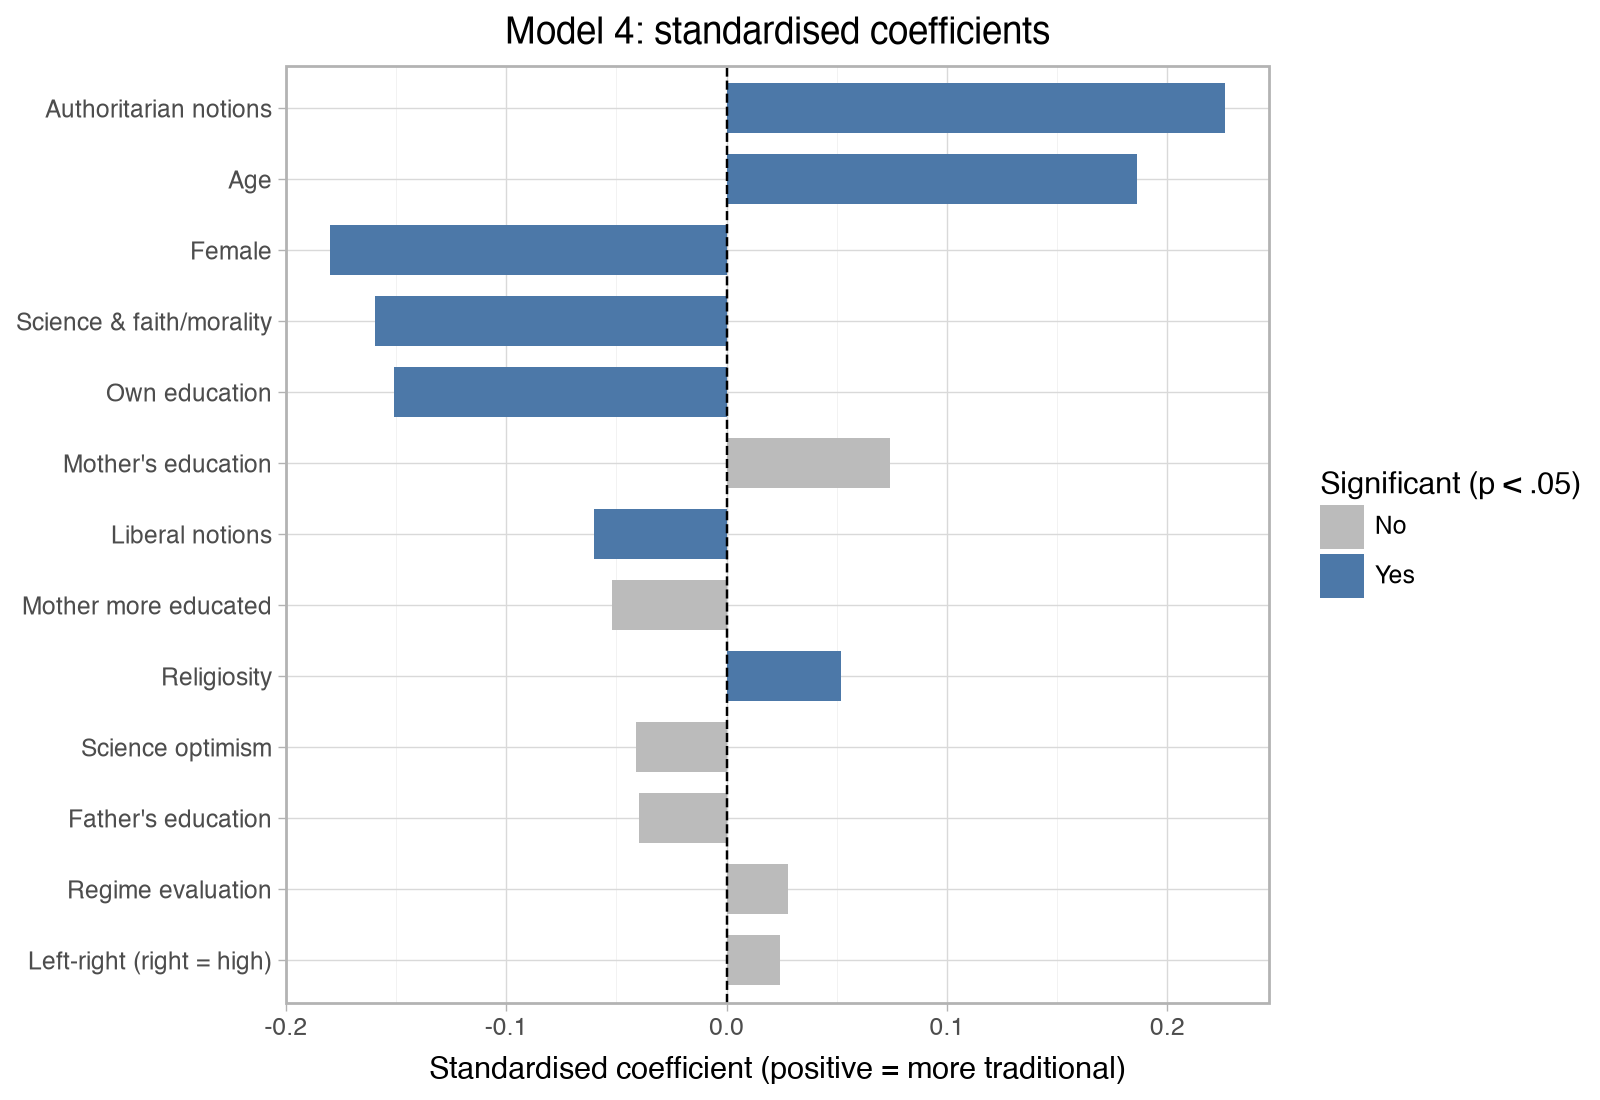

In [15]:
plot_betas = betas.reset_index().rename(columns={"index": "Variable"})  # data for the plot
plot_betas["Significant (p < .05)"] = np.where(plot_betas["p-value"] < 0.05, "Yes", "No")  # mark significant predictors
plot_betas["Variable"] = pd.Categorical(plot_betas["Variable"], categories=plot_betas["Variable"][::-1])  # largest at the top

p = (
    ggplot(plot_betas, aes(x="Variable", y="Standardised beta", fill="Significant (p < .05)"))  # one bar per predictor
    + geom_col(width=0.7)  # bars
    + geom_hline(yintercept=0, linetype="dashed")  # reference line at zero
    + coord_flip()  # horizontal bars, so the labels are easy to read
    + scale_fill_manual(values={"Yes": "#4C78A8", "No": "#BBBBBB"})  # blue = significant, grey = not significant
    + theme_light()  # clean background
    + labs(x="", y="Standardised coefficient (positive = more traditional)",  # axis labels
           title="Model 4: standardised coefficients")  # title
    + theme(figure_size=(8, 5.5))  # figure size
)
p.save(OUTPUT_FIGURES / "multivariate_model4_standardised_betas.png", dpi=300, verbose=False)  # save the figure
p  # display the figure

### Interpretation

In Model 4, the predictors with the **largest absolute standardised coefficients** are:

1. **Authoritarian notions of democracy (β = 0.226, p < .001):** the largest absolute standardised coefficient in Model 4. Respondents who see authoritarian features as essential to democracy are more traditional.
2. **Age (β = 0.186, p < .001):** older respondents are more traditional.
3. **Female (β = −0.180, p < .001):** women are less traditional than men.
4. **Science & faith/morality (β = −0.160, p < .001):** respondents who are less worried about science undermining morality are less traditional.
5. **Own education (β = −0.151, p < .001):** more educated respondents are less traditional.

**Liberal notions** (β = −0.060, p = .012) and **religiosity** (β = 0.052, p = .030) are significant but much smaller.

The **parental education variables have among the smallest standardised coefficients** in the full model: mother's education (β = 0.074, p = .060), mother more educated (β = −0.052, p = .073) and father's education (β = −0.040, p = .290). None of them is significant. Science optimism, regime evaluation and left–right placement are also not significant.

So, once respondents' own characteristics and values are in the model, parental education has little remaining association with gender-role attitudes. This does not mean parental education is irrelevant. As discussed under Model 4, its association overlaps with age/cohort and own education, and own education may be part of the pathway through which parental education is linked to attitudes. The authoritarian index also contains Q247 (equal incomes), whose conceptual fit is uncertain; Section 8.5 shows that its standardised coefficient is still the largest when Q247 is removed.

## 8. Robustness Checks

### 8.1 Model 4 Without Left–Right Placement

Left–right self-placement (Q240) is missing for 13.3% of respondents, and it was not significant in Model 4. To check that our conclusions are not caused by the smaller sample, we refit Model 4 without Q240 on the larger sample of respondents with complete data on the remaining variables.

In [16]:
preds_no240 = [p for p in predictors["Model 4"] if p != "Q240"]  # Model 4 predictors without Q240
sample_no240 = df.dropna(subset=[outcome] + preds_no240)  # larger complete-case sample
m4_no240 = smf.ols(f"{outcome} ~ " + " + ".join(preds_no240), data=sample_no240).fit()  # refit the model

robust = pd.DataFrame({  # compare the key coefficients
    "Model 4 (b)": m4.params[preds_no240], "Model 4 (p)": m4.pvalues[preds_no240],  # original Model 4
    "Without Q240 (b)": m4_no240.params[preds_no240], "Without Q240 (p)": m4_no240.pvalues[preds_no240],  # without Q240
})
robust.index = [labels[i] for i in robust.index]  # readable names
print(f"N: Model 4 = {int(m4.nobs)}, without Q240 = {int(m4_no240.nobs)}")  # the two sample sizes
print(f"R-squared without Q240 = {m4_no240.rsquared:.4f}")  # R-squared of the larger model
robust.round(4)  # display the table

N: Model 4 = 1442, without Q240 = 1588
R-squared without Q240 = 0.2564


,Model 4 (b),Model 4 (p),Without Q240 (b),Without Q240 (p)
Mother's education,0.0606,0.0597,0.0289,0.3597
Father's education,-0.0290,0.2902,-0.0242,0.3738
Mother more educated,-0.1159,0.0731,-0.0869,0.1708
Religiosity,0.0093,0.0300,0.0089,0.0364
Science optimism,-0.0150,0.1110,-0.0061,0.5015
Science & faith/morality,-0.0424,0.0000,-0.0396,0.0000
Authoritarian notions,0.0693,0.0000,0.0734,0.0000
Liberal notions,-0.0179,0.0115,-0.0292,0.0000
Regime evaluation,0.0090,0.2790,0.0058,0.4746
Female,-0.1929,0.0000,-0.2003,0.0000


### Interpretation

Dropping Q240 increases the sample from **1,442 to 1,588** respondents, and R² stays almost the same (**25.6%** vs. 25.3%). The conclusions do not change:

- All three **parental education** variables remain **non-significant** (p = .360, .374 and .171).
- **Authoritarian notions, science & faith/morality, liberal notions, religiosity, female, age and own education** remain significant, with very similar coefficients. Liberal notions becomes somewhat stronger (b = −0.0292, p < .001).
- **Science optimism** and **regime evaluation** remain non-significant.

This shows that our Model 4 results are not driven by the smaller sample caused by missing left–right answers.

### 8.2 Do the Key Interactions Survive the Controls?

In `07_moderation.ipynb`, four interactions remained significant after the Bonferroni correction, but those models did not include any control variables. We now add each of these interactions, one at a time, to a model with the parent's education, the moderator and the three controls (sex, age and own education). As in notebook 07, the parent's education and the moderator are centred, and each model is estimated on respondents with complete data on its own variables.

In [17]:
key_interactions = [  # the four interactions that passed the Bonferroni correction in notebook 07
    ("Q277R", "liberal_democracy"), ("Q278R", "science_faith_morality"),
    ("Q278R", "regime_evaluation"), ("Q277R", "authoritarian_democracy"),
]

rows = []  # list to collect the results
for parent, moderator in key_interactions:  # loop over the four interactions
    data = df.dropna(subset=[outcome, parent, moderator] + block4).copy()  # complete cases for this model
    for var in [parent, moderator]:  # centre the parent and the moderator, as in notebook 07
        data[f"{var}_c"] = data[var] - df[var].mean()  # subtract the full-sample mean
    formula = f"{outcome} ~ {parent}_c * {moderator}_c + female + Q262 + Q275R"  # interaction model with controls
    model = smf.ols(formula, data=data).fit()  # fit the model
    term = f"{parent}_c:{moderator}_c"  # name of the interaction term
    rows.append({"Interaction": f"{labels[parent]} × {labels[moderator]}", "N": int(model.nobs),  # labels and N
                 "b3 with controls": model.params[term], "SE": model.bse[term], "p-value": model.pvalues[term]})  # results

controlled = pd.DataFrame(rows)  # combine into one table
controlled.to_csv(OUTPUT_TABLES / "moderation_with_controls.csv", index=False)  # save the table
controlled.round(4)  # display the table

,Interaction,N,b3 with controls,SE,p-value
0,Mother's education × Liberal notions,1742,-0.0464,0.0104,0.000
1,Father's education × Science & faith/morality,1771,-0.0350,0.0081,0.000
2,Father's education × Regime evaluation,1743,0.0331,0.0100,0.001
3,Mother's education × Authoritarian notions,1702,0.0471,0.0111,0.000


### Interpretation

All four key interactions from `07_moderation.ipynb` **remain significant** after controlling for sex, age and own education, and are about the same size or slightly larger:

| Interaction | b3 without controls (notebook 07) | b3 with controls | p with controls |
|---|---|---|---|
| Mother's education × liberal notions | −0.0437 | **−0.0464** | < .001 |
| Father's education × science & faith/morality | −0.0339 | **−0.0350** | < .001 |
| Father's education × regime evaluation | 0.0336 | **0.0331** | .001 |
| Mother's education × authoritarian notions | 0.0356 | **0.0471** | < .001 |

This is an important result. Model 4 showed that the **average** association between parental education and gender-role attitudes disappears once age and own education are controlled for. Yet these interactions show that the strength of the link still depends on respondents' values, even with the controls included: parental education is linked to less traditional attitudes most strongly among respondents who hold liberal, non-authoritarian or secular views, and only weakly among the others. In other words, the average association hides differences between groups of respondents. However, `07_moderation.ipynb` (Section 8) shows that the **father × regime evaluation** interaction is not robust: it does not survive when parental education is entered as categories (with the Bonferroni threshold) or when both parents are in the same model. The other three interactions are more robust. (In these models the parental education slope is shown at the average value of the moderator. For the full picture across moderator levels, see the simple slopes in `07_moderation.ipynb`.)

### 8.3 HC3 Robust Standard Errors

The ordinary OLS standard errors assume that the spread of the residuals is the same for every respondent (**homoscedasticity**). Our outcome is bounded between 1 and 4, so this assumption may not hold. Respondents whose predicted score is near the edges of the scale cannot vary as much. **HC3 robust standard errors** do not rely on this assumption. The coefficients stay exactly the same, and only the standard errors, p-values and confidence intervals can change. We refit Model 4 with `cov_type="HC3"`, which is an option of the same `fit()` function we used in class.

In [18]:
m4_hc3 = smf.ols(f"{outcome} ~ " + " + ".join(predictors["Model 4"]), data=sample).fit(cov_type="HC3")  # Model 4 with HC3 robust SEs

hc3_table = pd.DataFrame({  # compare the model-based and robust results
    "b": m4.params, "SE (model-based)": m4.bse, "p (model-based)": m4.pvalues,  # original Model 4
    "SE (HC3)": m4_hc3.bse, "p (HC3)": m4_hc3.pvalues,  # robust version
}).drop("Intercept")
hc3_table.index = [labels[i] for i in hc3_table.index]  # readable names
hc3_table.to_csv(OUTPUT_TABLES / "multivariate_model4_hc3.csv")  # save the table
hc3_table.round(4)  # display the table

,b,SE (model-based),p (model-based),SE (HC3),p (HC3)
Mother's education,0.0606,0.0321,0.0597,0.0329,0.0655
Father's education,-0.0290,0.0274,0.2902,0.0266,0.2765
Mother more educated,-0.1159,0.0647,0.0731,0.0700,0.0978
Religiosity,0.0093,0.0043,0.0300,0.0042,0.0272
Science optimism,-0.0150,0.0094,0.1110,0.0098,0.1240
Science & faith/morality,-0.0424,0.0064,0.0000,0.0069,0.0000
Authoritarian notions,0.0693,0.0075,0.0000,0.0079,0.0000
Liberal notions,-0.0179,0.0071,0.0115,0.0074,0.0158
Regime evaluation,0.0090,0.0083,0.2790,0.0087,0.3006
Left-right (right = high),0.0064,0.0063,0.3108,0.0065,0.3221


### Interpretation

The robust standard errors are very close to the model-based ones, and **no conclusion changes**:

- Every predictor that was significant at the .05 level remains significant (e.g. liberal notions p = .012 → .016, religiosity p = .030 → .027; authoritarian notions, science & faith/morality, female, age and own education all p < .001).
- The three parental education variables remain **non-significant** (mother's education p = .060 → .066, mother more educated p = .073 → .098, father's education p = .290 → .277).

So the Model 4 results are not driven by unequal residual variance.

### 8.4 Parental Education as Categories

So far, parental education has been entered as a numeric score (1, 2, 3), which assumes that moving from Lower to Middle has the same association as moving from Middle to Higher. To check this, we enter mother's and father's education as **categories** with `C()`, as we did with categorical predictors in class. Each category is then compared with the **Lower** group, and no equal-spacing assumption is made.

We leave out `mother_more_educated` here. With both parents entered as categories it is almost fully determined by the dummies, and the point is to see the shape of each parent's association directly. We compare each categorical model with the matching numeric model using an F-test (`anova_lm`). A significant F-test means the numeric coding fits worse than the categories.

In [19]:
value_and_control_preds = block3 + block4  # the Model 3 and Model 4 additions
spec = {  # numeric and categorical versions of Model 1 and Model 4 (without mother_more_educated)
    "Model 1": ("Q277R + Q278R", "C(Q277R) + C(Q278R)"),
    "Model 4 (no mother_more_educated)": ("Q277R + Q278R + " + " + ".join(value_and_control_preds),
                                          "C(Q277R) + C(Q278R) + " + " + ".join(value_and_control_preds)),
}

cat_rows, cat_models = [], {}  # lists to collect the results
for name, (numeric_rhs, cat_rhs) in spec.items():  # loop over the two models
    numeric = smf.ols(f"{outcome} ~ {numeric_rhs}", data=sample).fit()  # numeric parental education
    categorical = smf.ols(f"{outcome} ~ {cat_rhs}", data=sample).fit()  # categorical parental education
    cat_models[name] = categorical  # store the categorical model
    f_test = anova_lm(numeric, categorical)  # does the categorical version fit better?
    for term in ["C(Q277R)[T.2.0]", "C(Q277R)[T.3.0]", "C(Q278R)[T.2.0]", "C(Q278R)[T.3.0]"]:  # the four dummies
        cat_rows.append({"Model": name, "Term": term.replace("C(Q277R)", "Mother").replace("C(Q278R)", "Father")
                         .replace("[T.2.0]", ": Middle vs Lower").replace("[T.3.0]", ": Higher vs Lower"),
                         "b": categorical.params[term], "p-value": categorical.pvalues[term],
                         "F-test numeric vs categories (p)": f_test["Pr(>F)"].iloc[1]})

categorical_table = pd.DataFrame(cat_rows)  # combine into a table
categorical_table.to_csv(OUTPUT_TABLES / "multivariate_categorical_parental_education.csv", index=False)  # save the table
categorical_table.round(4)  # display the table

,Model,Term,b,p-value,F-test numeric vs categories (p)
0,Model 1,Mother: Middle vs Lower,-0.0249,0.5431,0.1928
1,Model 1,Mother: Higher vs Lower,-0.1870,0.0026,0.1928
2,Model 1,Father: Middle vs Lower,-0.0740,0.0524,0.1928
3,Model 1,Father: Higher vs Lower,-0.1498,0.0057,0.1928
4,Model 4 (no mother_more_educated),Mother: Middle vs Lower,0.0873,0.0195,0.0259
5,Model 4 (no mother_more_educated),Mother: Higher vs Lower,0.0167,0.7640,0.0259
6,Model 4 (no mother_more_educated),Father: Middle vs Lower,0.0137,0.6902,0.0259
7,Model 4 (no mother_more_educated),Father: Higher vs Lower,-0.0210,0.6670,0.0259


In [20]:
# Joint test: are the four parental education dummies together significant in Model 4?
print(cat_models["Model 4 (no mother_more_educated)"].f_test(
    "C(Q277R)[T.2.0] = 0, C(Q277R)[T.3.0] = 0, C(Q278R)[T.2.0] = 0, C(Q278R)[T.3.0] = 0"))

<F test: F=2.1798432544034143, p=0.06908153058137143, df_denom=1.43e+03, df_num=4>


### Interpretation

**Model 1 (no controls).** The categories show that the association is concentrated in the **Higher** groups: compared with Lower, respondents with a highly educated mother score **0.187** points lower (p = .003) and those with a highly educated father **0.150** points lower (p = .006), while the Middle groups differ less (mother −0.025, p = .543; father −0.074, p = .052). The F-test does **not** show that the categories fit better than the numeric score (p = .193), so the numeric coding is a reasonable summary without controls.

**Model 4 (with values and controls).** Here the numeric coding fits **worse** than the categories (F-test p = .026). The categorical model reveals a pattern that the numeric score hides: respondents whose **mother had middle education** are slightly *more* traditional than those whose mother had lower education (b = **+0.087**, p = .020), while the Higher groups are close to the Lower group (mother +0.017, p = .764; father −0.021, p = .667). Taken together, the four parental education dummies are still not jointly significant (F = 2.18, p = .069).

This does not change our main conclusion: after adjustment for values, sex, age and own education, parental education has no clear remaining association with gender-role attitudes. But it shows that the adjusted association is **not linear**, so the single numeric coefficient in Model 4 should not be over-interpreted. The positive Middle coefficient is a single result from an exploratory check. It may reflect the respondents in the middle-education-mother group who are themselves *not* highly educated, and it could be a chance finding. A similar pattern appears in the item-level models of `10_item_level_logit.ipynb`.

### 8.5 Authoritarian Index Without Q247

The authoritarian index includes **Q247** ("the state makes people's incomes equal"). In `06_pca.ipynb` it was kept partly because it raised Cronbach's alpha. But a higher alpha does not guarantee that an item measures the intended concept, and support for equal incomes may reflect **economic egalitarianism** rather than authoritarianism. Because authoritarian notions have the largest standardised coefficient in Model 4, we refit Model 4 using the three-item version (`authoritarian_democracy_no247`: Q242, Q245, Q248) created in `06_pca.ipynb`. We also refit the mother × authoritarian interaction from Section 8.2.

In [21]:
preds_no247 = [p if p != "authoritarian_democracy" else "authoritarian_democracy_no247" for p in predictors["Model 4"]]  # swap the index
labels["authoritarian_democracy_no247"] = "Authoritarian notions (without Q247)"  # readable name
sample_no247 = df.dropna(subset=[outcome] + preds_no247)  # complete cases for this version
m4_no247 = smf.ols(f"{outcome} ~ " + " + ".join(preds_no247), data=sample_no247).fit()  # refit Model 4

z247 = sample_no247[[outcome] + preds_no247]  # variables for the standardised version
z247 = (z247 - z247.mean()) / z247.std()  # standardise every variable
m4_no247_std = smf.ols(f"{outcome} ~ " + " + ".join(preds_no247), data=z247).fit()  # standardised coefficients

no247_table = pd.DataFrame({"b": m4_no247.params, "p-value": m4_no247.pvalues,  # unstandardised results
                            "Standardised beta": m4_no247_std.params}).drop("Intercept")  # and the betas
no247_table.index = [labels[i] for i in no247_table.index]  # readable names
print(f"N = {int(m4_no247.nobs)}, R-squared = {m4_no247.rsquared:.4f}")  # sample size and R-squared

# Mother's education x authoritarian notions (without Q247), with controls, as in Section 8.2
data247 = df.dropna(subset=[outcome, "Q277R", "authoritarian_democracy_no247"] + block4).copy()  # complete cases
for var in ["Q277R", "authoritarian_democracy_no247"]:  # centre both variables
    data247[f"{var}_c"] = data247[var] - df[var].mean()
int247 = smf.ols(f"{outcome} ~ Q277R_c * authoritarian_democracy_no247_c + female + Q262 + Q275R", data=data247).fit()
term247 = "Q277R_c:authoritarian_democracy_no247_c"  # name of the interaction term
print(f"Mother's education x authoritarian (without Q247), with controls: b3 = {int247.params[term247]:.4f}, "
      f"p = {int247.pvalues[term247]:.4g}, N = {int(int247.nobs)}")

no247_table.to_csv(OUTPUT_TABLES / "multivariate_model4_authoritarian_no247.csv")  # save the table
no247_table.round(4)  # display the table

N = 1444, R-squared = 0.2465
Mother's education x authoritarian (without Q247), with controls: b3 = 0.0508, p = 2.171e-06, N = 1709


,b,p-value,Standardised beta
Mother's education,0.0607,0.0600,0.0744
Father's education,-0.0287,0.2969,-0.0391
Mother more educated,-0.1134,0.0807,-0.0509
Religiosity,0.0085,0.0480,0.0477
Science optimism,-0.0151,0.1103,-0.0414
Science & faith/morality,-0.0442,0.0000,-0.1666
Authoritarian notions (without Q247),0.0634,0.0000,0.2105
Liberal notions,-0.0142,0.0460,-0.0477
Regime evaluation,0.0071,0.3978,0.0220
Left-right (right = high),0.0081,0.2049,0.0303


### Interpretation

Removing Q247 makes **no substantive difference**. The two versions of the index are highly correlated (r = .94, see `06_pca.ipynb`).

- In Model 4 (N = 1,444, R² = 24.7% vs. 25.3%), authoritarian notions without Q247 remain strongly significant (b = 0.063, p < .001), and they still have the **largest absolute standardised coefficient** (β = 0.210), followed by age, female, science & faith/morality and own education, as before.
- The parental education variables remain non-significant (p = .060, .081 and .297). Liberal notions (p = .046) and religiosity (p = .048) remain just significant.
- The mother's education × authoritarian interaction with controls is, if anything, slightly **stronger** without Q247 (b3 = 0.051, p < .001, vs. 0.047 with Q247).

So the authoritarian results are not driven by the equal-incomes item. Still, the index label should be read as "seeing non-democratic features (religious authorities, army rule, obedience to rulers) as essential to democracy". It does not describe respondents' own authoritarian personality.

## Summary

- **Model 1:** both mother's (b = −0.075) and father's education (b = −0.072) are significantly associated with less traditional attitudes, but together they account for only **3.0%** of the variance.
- **Model 2:** `mother_more_educated` adds a significant extra association (b = −0.218, p = .003; ΔR² = 0.61%). Because this variable is fully determined by the two parents' education levels, its coefficient should be read as a departure from the numeric parental-education pattern, not as the effect of changing the gap while holding both parents constant.
- **Model 3:** adding respondents' values increases R² by **12.4** percentage points. Authoritarian notions of democracy and science & faith/morality have the clearest associations. Father's education and `mother_more_educated` remain significant.
- **Model 4:** adding sex, age and own education increases R² by a further **9.2** points (final R² = **25.3%**). **The parental education coefficients are substantially attenuated and no longer significant.** Respondents with more educated parents are younger and more educated themselves. Because own education may lie on the pathway between parental education and attitudes, this model cannot tell whether own education is a confounder or a mediator, and the age association may reflect age or cohort differences.
- **R² increments are order-dependent:** if the demographic block is added before the values block, the increments become 10.9 and 10.8 points instead of 9.2 and 12.4.
- **Largest absolute standardised coefficients** in Model 4: authoritarian notions (β = 0.23), age (β = 0.19), female (β = −0.18), science & faith/morality (β = −0.16) and own education (β = −0.15).
- **Multicollinearity:** all VIFs are below 3. The highest are for mother's (2.97) and father's (2.67) education, which reflects their correlation (r = .68) but is not a serious problem.
- **Robustness:** the results are the same without Q240, with **HC3 robust standard errors**, and with the **authoritarian index without Q247**. With parental education entered as **categories**, the Model 4 association turns out to be non-linear (middle-educated mothers are slightly *more* traditional than lower-educated ones, p = .020), although the parental dummies are not jointly significant (p = .069). Three of the four key interactions from `07_moderation.ipynb` remain significant after adding the controls and are also robust in the checks in notebook 07. The father × regime evaluation interaction is less robust.

**Limitations:**
- **Cross-sectional data:** we cannot establish causal direction or separate age from cohort effects. Own education may come between parental education and attitudes (a pathway), which our models cannot test formally.
- **Self-reported parental education:** respondents report their parents' education, which may contain errors, especially for older respondents.
- **Grouped education levels:** treating them as numeric scores is a simplification that does not hold after adjustment (Section 8.4).
- **Complete-case analysis:** the main sample uses only the 1,442 respondents with complete data.
- **Unweighted data:** the analyses are not weighted to the Singapore population.